# 01 — Bubble detection
Cached per split, sequence and page.

Use .venvAppliedTask.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "project.json").is_file():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pipeline_helpers as P
import json
from PIL import Image, ImageDraw, ImageFont
ROOT = P.ROOT
MODELS = P.read_json(ROOT / "models.json")
SPLITS = ["train", "val"]  # Or ["train"] / ["val"].
FORCE_RERUN = False
items = P.pages(SPLITS)
print("Pages:", len(items))
import math
from ultralytics import YOLO
MODEL = Path(MODELS["bubble_detection"]["local_path"])
CONFIDENCE = 0.25
if not MODEL.is_file():
    raise FileNotFoundError(MODEL)
model = None  # Loaded only if a page needs detection.


Pages: 240


Detect uncached pages. Raw bubble IDs are preserved through cleanup.

In [2]:
for item in items:
    PAGE = Path(item["image_path"])
    page = Image.open(PAGE).convert("RGB")
    OUT = P.page_folder(item)
    OUT.mkdir(parents=True, exist_ok=True)
    settings = {"confidence":CONFIDENCE, "imgsz":1024, "version":1}
    dependencies = [MODEL]
    def save_stage(name, records):
        P.save_stage(item, name, records, settings, dependencies)
    def load_stage(name):
        return P.load_stage(item, name)
    if all(P.cached(item, name, settings, dependencies, FORCE_RERUN) for name in ['bubbles.json']):
        print("Cached:", item["split"], item["sequence_id"], item["page_number"])
        continue
    if model is None:
        model = YOLO(str(MODEL))
    result = model.predict(source=page, imgsz=1024, conf=CONFIDENCE, verbose=False)[0]
    bubbles = []
    for box, score in zip(result.boxes.xyxy.cpu().tolist(), result.boxes.conf.cpu().tolist()):
        x1, y1, x2, y2 = box
        bounds = [max(0, math.floor(x1)), max(0, math.floor(y1)),
                  min(page.width, math.ceil(x2)), min(page.height, math.ceil(y2))]
        if bounds[2] > bounds[0] and bounds[3] > bounds[1]:
            bubbles.append({"box": bounds, "confidence": float(score)})
    bubbles.sort(key=lambda b: (b["box"][1], -b["box"][0]))
    for i, bubble in enumerate(bubbles, 1):
        bubble["bubble_id"] = f"B{i}"
    save_stage("bubbles.json", bubbles)
    print(f"Detected {len(bubbles)} bubbles")


Cached: train seq_2032620aa4e4ac7f 1
Cached: train seq_2032620aa4e4ac7f 2
Cached: train seq_2032620aa4e4ac7f 3
Cached: train seq_952f154fb1505883 1
Cached: train seq_952f154fb1505883 2
Cached: train seq_952f154fb1505883 3
Cached: train seq_7db7a000adeceacf 1
Cached: train seq_7db7a000adeceacf 2
Cached: train seq_7db7a000adeceacf 3
Cached: train seq_9032e5551cf1a9d2 1
Cached: train seq_9032e5551cf1a9d2 2
Cached: train seq_9032e5551cf1a9d2 3
Cached: train seq_2022b8c0e1f2d3c0 1
Cached: train seq_2022b8c0e1f2d3c0 2
Cached: train seq_2022b8c0e1f2d3c0 3
Cached: train seq_a3bd36201a0cd61b 1
Cached: train seq_a3bd36201a0cd61b 2
Cached: train seq_a3bd36201a0cd61b 3
Cached: train seq_72fdfff4b4353a42 1
Cached: train seq_72fdfff4b4353a42 2
Cached: train seq_72fdfff4b4353a42 3
Cached: train seq_b251c8e1ba8b91f8 1
Cached: train seq_b251c8e1ba8b91f8 2
Cached: train seq_b251c8e1ba8b91f8 3
Cached: val seq_ee880b9612205860 1
Cached: val seq_ee880b9612205860 2
Cached: val seq_ee880b9612205860 3
Cached:

## View saved results
These cells only read saved results. They do not run models or change cached files. Training shows targets and run-wide loss history; validation shows saved predictions.

In [3]:
from pathlib import Path
import sys, importlib
view_root = Path.cwd().resolve()
if not (view_root / "project.json").is_file():
    view_root = view_root.parent
sys.path.insert(0, str(view_root))
import result_viewer as V
importlib.reload(V)
VIEW_STAGE = 'bubbles'
VIEW_SPLIT = "train"  # Or "val".
VIEW_RUN = None


### 1. View a random page
Rerun this cell to choose another page with a saved result in this split.


train | seq_fb6d15ad78b7191c | page 1


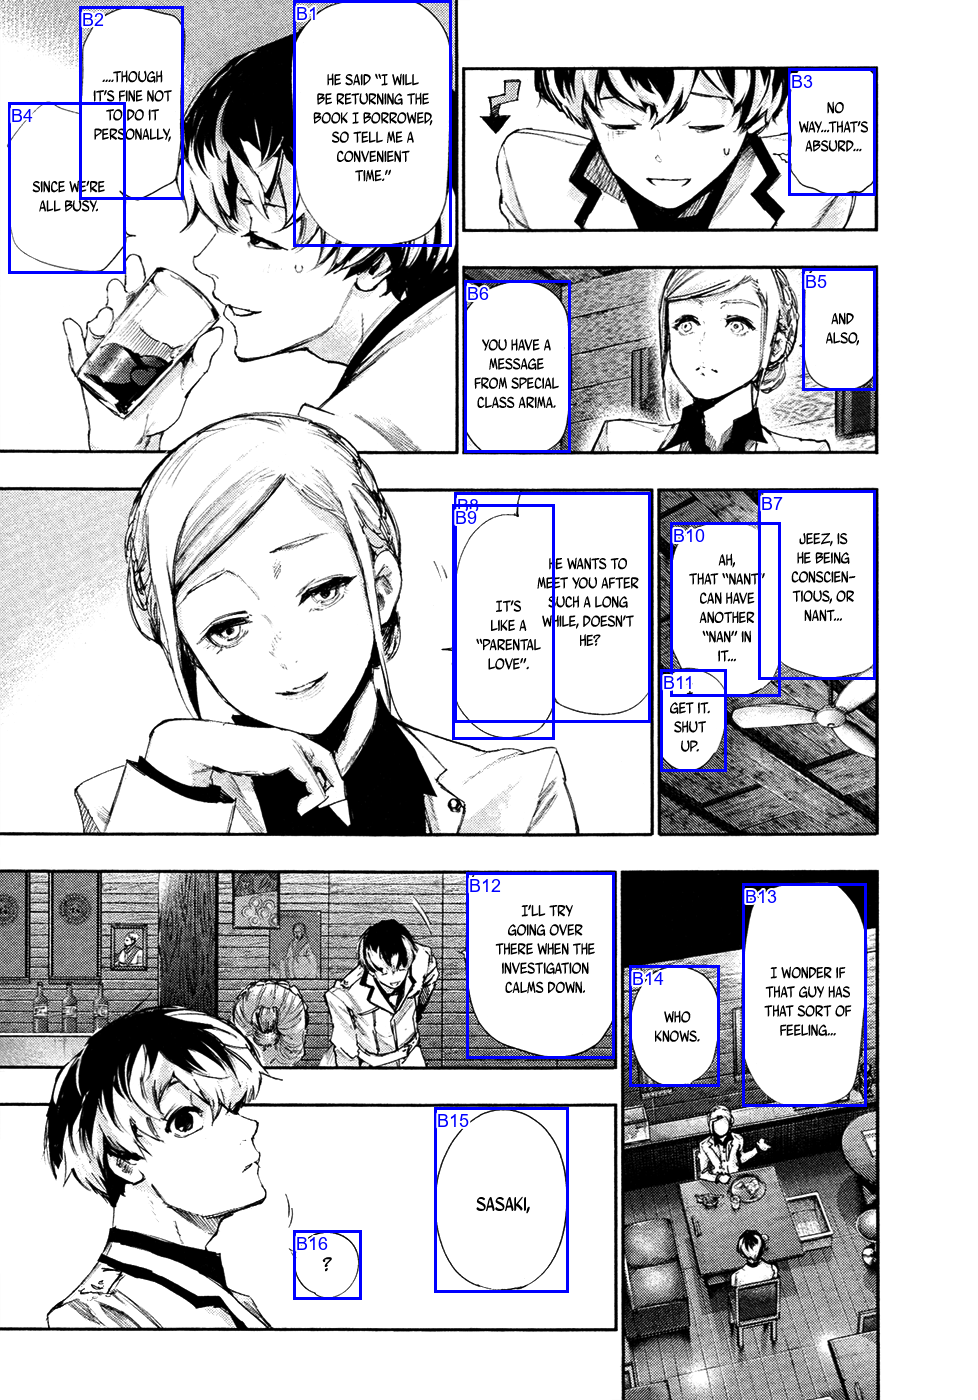

[
  {
    "box": [
      293,
      0,
      451,
      246
    ],
    "confidence": 0.9502992630004883,
    "bubble_id": "B1"
  },
  {
    "box": [
      79,
      6,
      183,
      199
    ],
    "confidence": 0.9477481245994568,
    "bubble_id": "B2"
  },
  {
    "box": [
      788,
      68,
      875,
      195
    ],
    "confidence": 0.9477453827857971,
    "bubble_id": "B3"
  },
  {
    "box": [
      8,
      102,
      125,
      273
    ],
    "confidence": 0.9388846755027771,
    "bubble_id": "B4"
  },
  {
    "box": [
      802,
      268,
      875,
      390
    ],
    "confidence": 0.9442927837371826,
    "bubble_id": "B5"
  },
  {
    "box": [
      464,
      280,
      570,
      452
    ],
    "confidence": 0.9501252174377441,
    "bubble_id": "B6"
  },
  {
    "box": [
      758,
      490,
      875,
      679
    ],
    "confidence": 0.9445473551750183,
    "bubble_id": "B7"
  },
  {
    "box": [
      454,
      492,
      650,
      722
    ],
    "confidence

In [4]:
viewed_page = V.show_random(VIEW_STAGE, split=VIEW_SPLIT, run_folder=VIEW_RUN)


### 2. View all pages of a sequence
Enter a sequence ID, or leave it empty to use the random page’s sequence. Missing stage results are reported for each page.


train | seq_fb6d15ad78b7191c | page 1


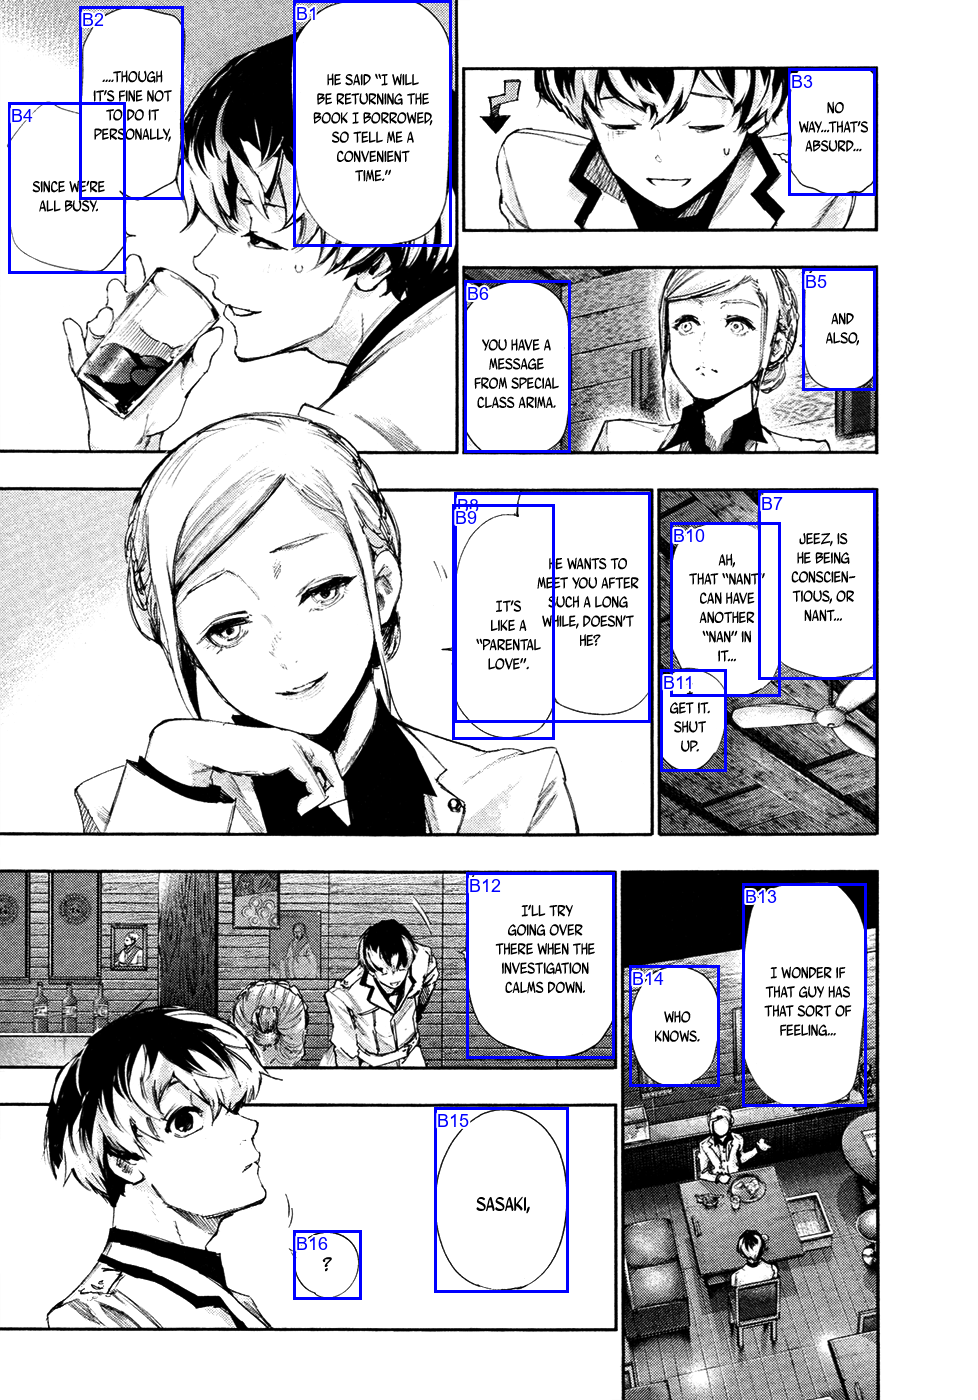

[
  {
    "box": [
      293,
      0,
      451,
      246
    ],
    "confidence": 0.9502992630004883,
    "bubble_id": "B1"
  },
  {
    "box": [
      79,
      6,
      183,
      199
    ],
    "confidence": 0.9477481245994568,
    "bubble_id": "B2"
  },
  {
    "box": [
      788,
      68,
      875,
      195
    ],
    "confidence": 0.9477453827857971,
    "bubble_id": "B3"
  },
  {
    "box": [
      8,
      102,
      125,
      273
    ],
    "confidence": 0.9388846755027771,
    "bubble_id": "B4"
  },
  {
    "box": [
      802,
      268,
      875,
      390
    ],
    "confidence": 0.9442927837371826,
    "bubble_id": "B5"
  },
  {
    "box": [
      464,
      280,
      570,
      452
    ],
    "confidence": 0.9501252174377441,
    "bubble_id": "B6"
  },
  {
    "box": [
      758,
      490,
      875,
      679
    ],
    "confidence": 0.9445473551750183,
    "bubble_id": "B7"
  },
  {
    "box": [
      454,
      492,
      650,
      722
    ],
    "confidence

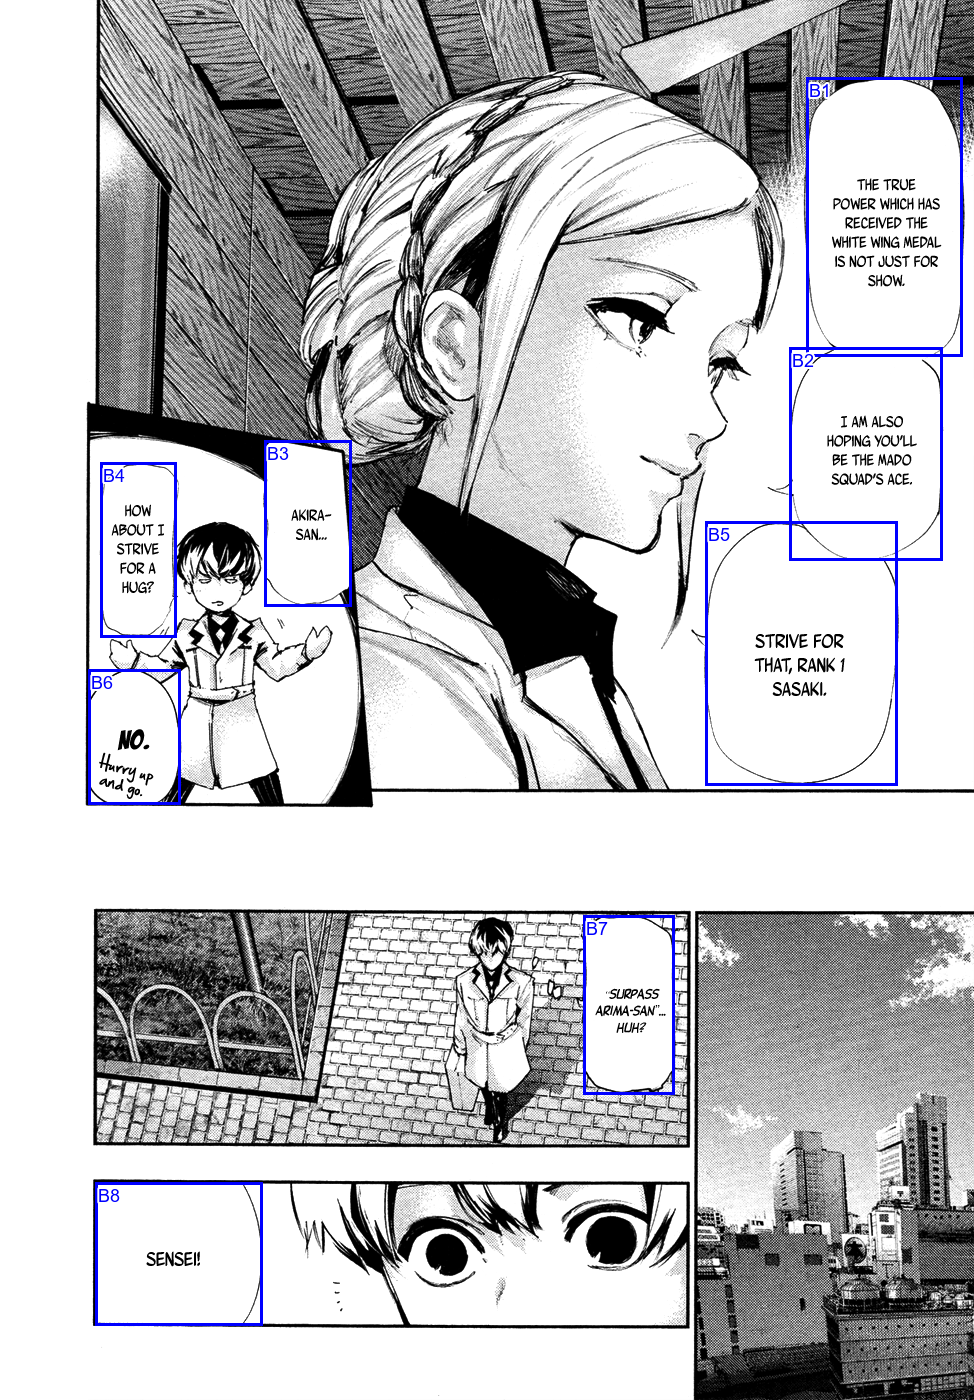

[
  {
    "box": [
      806,
      77,
      962,
      356
    ],
    "confidence": 0.952404260635376,
    "bubble_id": "B1"
  },
  {
    "box": [
      789,
      347,
      942,
      560
    ],
    "confidence": 0.9328711628913879,
    "bubble_id": "B2"
  },
  {
    "box": [
      264,
      440,
      351,
      606
    ],
    "confidence": 0.9345263838768005,
    "bubble_id": "B3"
  },
  {
    "box": [
      100,
      462,
      176,
      637
    ],
    "confidence": 0.94112229347229,
    "bubble_id": "B4"
  },
  {
    "box": [
      705,
      521,
      897,
      785
    ],
    "confidence": 0.9571337103843689,
    "bubble_id": "B5"
  },
  {
    "box": [
      88,
      669,
      180,
      804
    ],
    "confidence": 0.944200873374939,
    "bubble_id": "B6"
  },
  {
    "box": [
      583,
      915,
      674,
      1094
    ],
    "confidence": 0.9487530589103699,
    "bubble_id": "B7"
  },
  {
    "box": [
      95,
      1182,
      262,
      1325
    ],
    "confid

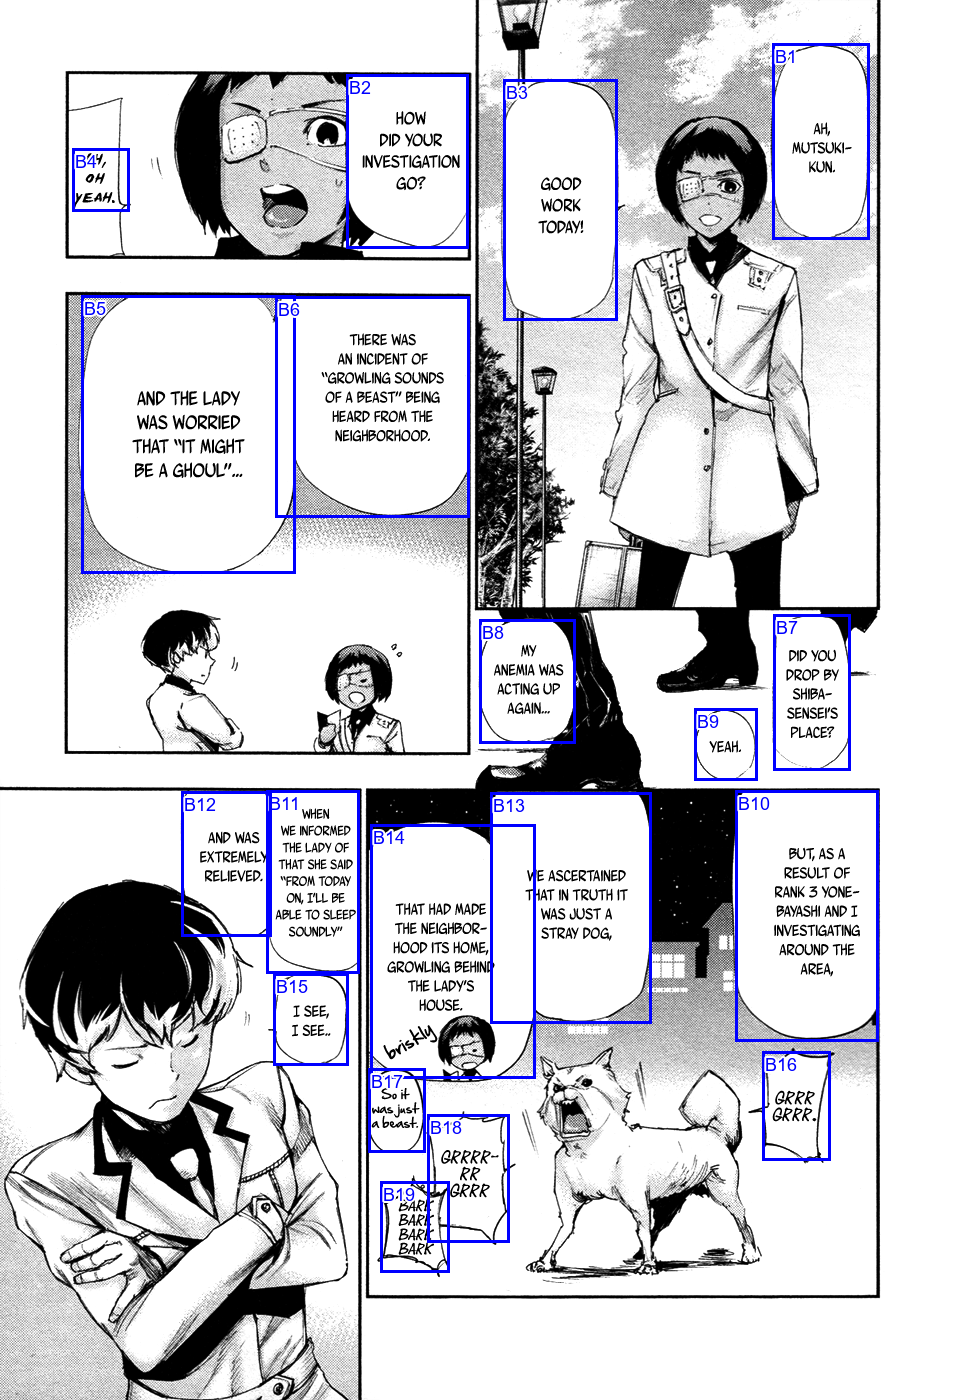

[
  {
    "box": [
      772,
      43,
      869,
      239
    ],
    "confidence": 0.9459674954414368,
    "bubble_id": "B1"
  },
  {
    "box": [
      346,
      74,
      468,
      248
    ],
    "confidence": 0.9540499448776245,
    "bubble_id": "B2"
  },
  {
    "box": [
      503,
      79,
      617,
      320
    ],
    "confidence": 0.9588791131973267,
    "bubble_id": "B3"
  },
  {
    "box": [
      72,
      148,
      129,
      211
    ],
    "confidence": 0.5098209977149963,
    "bubble_id": "B4"
  },
  {
    "box": [
      81,
      295,
      295,
      573
    ],
    "confidence": 0.957216203212738,
    "bubble_id": "B5"
  },
  {
    "box": [
      275,
      296,
      469,
      517
    ],
    "confidence": 0.9507198333740234,
    "bubble_id": "B6"
  },
  {
    "box": [
      773,
      614,
      850,
      770
    ],
    "confidence": 0.9425541162490845,
    "bubble_id": "B7"
  },
  {
    "box": [
      479,
      619,
      575,
      743
    ],
    "confiden

In [5]:
VIEW_SEQUENCE_ID = ""  # Example: "seq_71033fec4de494fc"
sequence_to_view = VIEW_SEQUENCE_ID or (viewed_page["sequence_id"] if viewed_page else "")
if sequence_to_view:
    V.show_sequence(sequence_to_view, VIEW_STAGE, split=VIEW_SPLIT, run_folder=VIEW_RUN)
else:
    print("Set VIEW_SEQUENCE_ID to a sequence in VIEW_SPLIT.")
